In [48]:
import pandas as pd
import seaborn as sns 
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.pyplot as plt

In [49]:
df = pd.read_csv('/home/MRMelissaGrantPeters/MinaRyten/Melissa/MRIxST/processed_data/11_transcriptomics/annot_l2_enrich_test_lists_fdr_all.csv')
df

,annot_level,tissue,assay,comparison,direction,p_value,p_adjust,test_enrichment
0,2,F,Astro,PDControl,Down-regulated,0.045053,0.045053,myelin_structural_proteins
1,2,P,Astro,PDControl,Down-regulated,0.032207,0.045053,myelin_structural_proteins
2,2,F,Astro,PDControl,Down-regulated,0.000319,0.004152,oligo_maturation
3,2,F,OPC,PDControl,Down-regulated,0.008665,0.056322,oligo_maturation
4,2,C,OPC,PDControl,Down-regulated,0.054643,0.236788,oligo_maturation
5,2,C,Astro,PDControl,Down-regulated,0.097134,0.252548,oligo_maturation
6,2,F,Astro,PDControl,Up-regulated,0.091997,0.252548,oligo_maturation
7,2,C,IN,PDControl,Up-regulated,0.167949,0.322916,oligo_maturation
8,2,F,Endomural,PDControl,Up-regulated,0.223557,0.322916,oligo_maturation
9,2,P,Astro,PDControl,Down-regulated,0.191756,0.322916,oligo_maturation


In [50]:
df_mat = df[df['test_enrichment']=='oligo_maturation']

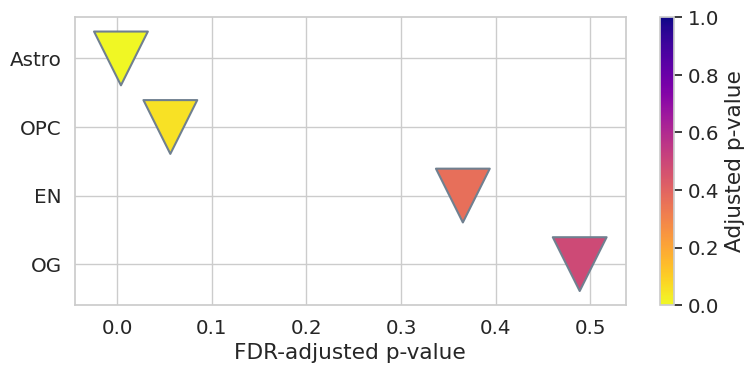

In [74]:
sns.set(font_scale = 1.3, style = "whitegrid")

plotting = df_mat[df_mat['tissue']=='F']
plotting = plotting[plotting['direction']=='Down-regulated']
#plotting = filtered_OGs[filtered_OGs['annot_level']==1]

sns.set_style("whitegrid")

# Normalize p.adjust values
norm = mcolors.Normalize(vmin=0, vmax=1)
cmap = cm.plasma_r

# Scale GeneRatio for triangle size
size_scale = 1500
sizes = 1 * size_scale

# Create the plot
fig, ax = plt.subplots(figsize=(8, 4))
# Expand borders to fit triangles
#ax.set_ylim(-1, len(plotting["p_adjust"]) - 1)
#ax.set_xlim(4 * 0.87, 4 * 1.04)
ax.margins(x=0.1, y=0.2)  # 5% extra space on each side
# Actually plot
sns.scatterplot(
    x=plotting["p_adjust"],
    y=plotting["assay"],
    s=sizes,
    marker="v",  # downward-facing triangle
    hue = plotting["p_adjust"],
    hue_norm = (0,1),
    palette = 'plasma_r',
    edgecolor='slategrey',
    linewidth=1.5,
    ax=ax
)

# Add colorbar
sm = cm.ScalarMappable(cmap=cmap)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("Adjusted p-value")

# Fix labels
ax.set_xlabel("FDR-adjusted p-value")
ax.set_ylabel("")
ax.legend_.remove()
plt.tight_layout()
plt.savefig('../../plots/11_transcriptomics/srnaseq_oligo_maturation.png', dpi = 300, bbox_inches = 'tight')
plt.show()

In [ ]:
all_overlaps = pd.read_csv('processed_data/all_overlaps.csv', sep = '\t')
all_overlaps.rename(columns = {'disease_list':'test_enrichment'}, inplace = True)
all_overlaps.replace({'human_DAO_list':'DAO', 'human_IFN_list':'IFN', 'Myelin_sheath':'Myelin sheath'}, inplace = True)

new_df = pd.merge(
    left=all_overlaps, 
    right=df,
    how='left',
    left_on=['assay', 'tissue', 'annot_level', 'comparison', 'test_enrichment'],
    right_on=['assay', 'tissue', 'annot_level', 'comparison', 'test_enrichment'],
)
new_df.to_csv('processed_data/03-annot_2_enrich_overlap_all.csv')
l3 = new_df[new_df['annot_level']==2]
#OG = l4[l4['assay'].str.startswith('OG') | l4['assay'].str.startswith('OPC')]
l3 = l3.fillna(1)
l3_C = l3[l3['tissue']=='C'].pivot('assay', 'test_enrichment', 'perc_disease_gene') 
l3_F = l3[l3['tissue']=='F'].pivot('assay', 'test_enrichment', 'perc_disease_gene') 
l3_P = l3[l3['tissue']=='P'].pivot('assay', 'test_enrichment', 'perc_disease_gene')

pval_C = l3[l3['tissue']=='C'].pivot('assay', 'test_enrichment', 'p_adjust') 
pval_F = l3[l3['tissue']=='F'].pivot('assay', 'test_enrichment', 'p_adjust') 
pval_P = l3[l3['tissue']=='P'].pivot('assay', 'test_enrichment', 'p_adjust')

fig, axes = plt.subplots(1, 3, figsize=(10, 5), sharey=True)
vmax_all = 15

hm1 = sns.heatmap(l3_C, ax=axes[0], cmap='Reds', vmax = vmax_all, cbar=False)
axes[0].set_title("Cingulate")
axes[0].set_xlabel('')
axes[0].set_ylabel('')

hm2 = sns.heatmap(l3_F, ax=axes[1], cmap='Reds', vmax = vmax_all, cbar=False)
axes[1].set_title("Frontal")
axes[1].set_xlabel('')
axes[1].set_ylabel('')

hm3 = sns.heatmap(l3_P, ax=axes[2], cmap='Reds', vmax = vmax_all, cbar=False)
axes[2].set_title("Parietal")
axes[2].set_xlabel('')
axes[2].set_ylabel('')

for ax in axes:
    rect = patches.Rectangle(
        (0, 0), 1, 1, transform=ax.transAxes,  # full axes
        linewidth=3, edgecolor='darkgrey', facecolor='none'
    )
    ax.add_patch(rect)
    


# Overlay rectangles for significant p-values
for ax, pvals in zip(axes, [pval_C, pval_F, pval_P]):
    nrows, ncols = pvals.shape
    for i in range(nrows):
        for j in range(ncols):
            if pvals.iloc[i, j] < 0.05:
                rect = patches.Rectangle(
                    (j, i), 1, 1,
                    linewidth=2, edgecolor='black', facecolor='none'
                )
                ax.add_patch(rect)


fig.colorbar(hm3.collections[0], ax=axes, orientation='horizontal', fraction=0.03, pad=-0.2)

plt.tight_layout()
plt.savefig('plots/list_enrichment_level2.png', dpi = 300, bbox_inches = 'tight')
plt.show()